# Clause triage — a decision tree over the YojanaMitra annotation backlog

**Course project · YojanaMitra · NLP**

---

## What this model does, and what it deliberately does not

This is **not** an eligibility model. Nothing in this notebook decides whether a
citizen qualifies for a scheme. That decision is made by a deterministic rule
engine acting only on clauses a named human reviewer has approved, and every
verdict it produces quotes the exact sentence from the scheme document that
justified it. A learned model cannot do that, which is why it is kept out of
that path entirely.

What this model does is **triage the annotation backlog**. Ingesting 2,066
government scheme documents produced **11,551 eligibility clauses**, and each one
needs a different kind of human attention:

| Class | What a reviewer has to do | n |
|---|---|---|
| `machine_checkable` | Confirm or correct a constraint that was already drafted | 4,962 |
| `no_pattern` | Write a constraint by hand — nothing matched | 5,089 |
| `needs_schema_extension` | Checkable in principle, but the profile schema lacks the field | 705 |
| `not_machine_checkable` | Mark as un-checkable ("subject to fund availability") | 795 |

Predicting the class lets a reviewer work the cheap clauses first and see the
expensive ones coming. That is a real supervised problem with 11,551 labelled
examples.

## The circularity, stated before the results

The labels were produced by the **rule-based proposer**, not by humans. A model
trained on them learns *the proposer's rules*, not ground truth about clauses.
This is **distillation**, and reporting it as anything else would be dishonest.

It is still worth doing, and the experiment is designed around the objection:

* **Model A** uses only *structural* features — length, punctuation, digit
  density, position in the document. The proposer never looks at any of them. If
  A beats the baseline, the classes reflect something real about how clauses are
  written, not merely the regexes that labelled them.
* **Model B** adds readable lexical cues. This is the practical model.
* **Model C** uses TF-IDF. It is the accuracy ceiling and is not interpretable —
  included to show what is being given up.

In [1]:
%matplotlib inline

import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEED = 20260915
np.random.seed(SEED)

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
})

BRAND, YES, MAYBE, NO = '#134e8f', '#136c34', '#8a5a00', '#8c2f27'

CLAUSES = Path('..') / 'data' / 'annotations' / 'clauses.json'
if not CLAUSES.exists():
    CLAUSES = Path('data') / 'annotations' / 'clauses.json'
print('reading', CLAUSES.resolve())

reading data/annotations/clauses.json


## 1 · Labels

The three annotation states hide the most useful distinction. `proposed` covers
both *"a constraint was drafted"* and *"no pattern matched at all"*, and those
need completely different work from a reviewer. Splitting them also moves the
majority class from 87% to 44%, which is what makes the problem worth modelling.

In [2]:
def label_of(clause):
    state = clause['annotation_state']
    if state == 'proposed':
        return 'machine_checkable' if clause.get('constraint') else 'no_pattern'
    return state

raw = json.loads(CLAUSES.read_text(encoding='utf-8'))
print(f'{len(raw):,} clauses from {len({c["scheme_id"] for c in raw}):,} schemes')

11,551 clauses from 2,064 schemes


## 2 · Features

### Model A — structural only

Shape, not vocabulary. Nothing here is a word the proposer matches on. This is
the control: if a tree built from these alone beats the baseline, the categories
are not purely artefacts of the regexes that assigned them.

In [3]:
NUM_RE  = re.compile(r'\d')
YEAR_RE = re.compile(r'\b(19|20)\d{2}\b')

def structural_features(text, position, total_in_scheme):
    words = text.split()
    n_words = len(words) or 1
    return {
        'n_chars': len(text),
        'n_words': n_words,
        'avg_word_len': sum(len(w) for w in words) / n_words,
        'n_commas': text.count(','),
        'n_semicolons': text.count(';'),
        'n_parens': text.count('('),
        'n_slashes': text.count('/'),
        'n_digits': len(NUM_RE.findall(text)),
        'digit_density': len(NUM_RE.findall(text)) / max(len(text), 1),
        'n_uppercase_words': sum(1 for w in words if w.isupper() and len(w) > 1),
        'ends_with_colon': int(text.rstrip().endswith(':')),
        'starts_upper': int(bool(text[:1].isupper())),
        'has_year': int(bool(YEAR_RE.search(text))),
        # Eligibility sections tend to open with hard criteria and trail off into
        # procedural notes, so position carries signal.
        'position': position,
        'position_frac': position / max(total_in_scheme, 1),
        'clauses_in_scheme': total_in_scheme,
    }

### Model B — plus readable cues

Plain-English cues a reviewer would recognise on sight. These **do** overlap with
what the proposer looks for. Model B is the practical model; Model A is the
honest one.

In [4]:
CUES = {
    'cue_age':            r'\b(age|aged|years? old|व(र्ष|य)|ఏళ్ల)\b',
    'cue_income':         r'\b(income|salary|earning|annual income|आय|ఆదాయ)\b',
    'cue_money':          r'(₹|rs\.?|rupees|lakh|crore)',
    'cue_land':           r'\b(acre|hectare|land ?holding|एकड़|ఎకర)\b',
    'cue_gender':         r'\b(women|woman|female|male|girl|transgender)\b',
    'cue_category':       r'\b(sc|st|obc|ews|scheduled caste|scheduled tribe|general category)\b',
    'cue_state_resident': r'\b(resident|domicile|native of|permanent resident)\b',
    'cue_occupation':     r'\b(farmer|weaver|artisan|labour|worker|entrepreneur|student)\b',
    'cue_education':      r'\b(class|std|standard|matric|graduate|diploma|school|college)\b',
    'cue_negation':       r'\b(not|no|except|excluding|ineligible|shall not|must not)\b',
    'cue_modal_must':     r'\b(must|should|shall|required to|has to)\b',
    'cue_document':       r'\b(certificate|aadhaar|ration card|document|proof|affidavit)\b',
    'cue_procedure':      r'\b(apply|application|submit|portal|registration|website)\b',
    'cue_vague':          r'\b(subject to|as per|may be|discretion|availability|from time to time)\b',
    'cue_range':          r'\b(between|from .* to |up ?to|minimum|maximum|at least|not exceed)\b',
}
CUE_RES = {k: re.compile(v, re.I) for k, v in CUES.items()}

def cue_features(text):
    return {k: int(bool(r.search(text))) for k, r in CUE_RES.items()}

## 3 · Building the frame

Note `group`. Identical clause text recurs across hundreds of schemes — 11,551
clauses collapse to 9,825 distinct sentences. The dedup group id becomes the
grouping key for cross-validation; without it the same sentence lands in train
and test and every score below would be fiction.

In [5]:
by_scheme = {}
for c in raw:
    by_scheme[c['scheme_id']] = by_scheme.get(c['scheme_id'], 0) + 1

seen, rows = {}, []
for c in raw:
    sid = c['scheme_id']
    pos = seen.get(sid, 0); seen[sid] = pos + 1
    text = c['source_text']
    row = {
        'id': c['id'], 'scheme_id': sid,
        'group': c.get('dedup_group_id') or c['id'],
        'text': text, 'label': label_of(c),
    }
    row.update(structural_features(text, pos, by_scheme[sid]))
    row.update(cue_features(text))
    rows.append(row)

df = pd.DataFrame(rows)
structural_cols = list(structural_features('x', 0, 1).keys())
cue_cols = list(CUES.keys())

print(f'clauses      : {len(df):,}')
print(f'schemes      : {df.scheme_id.nunique():,}')
print(f'dedup groups : {df.group.nunique():,}   <- CV grouping key')
print()
print(df.label.value_counts().to_string())
print(f'\nmajority class: {df.label.value_counts(normalize=True).max():.1%}'
      '  — so accuracy is a useless metric; everything below is macro-F1')

clauses      : 11,551
schemes      : 2,064
dedup groups : 9,825   <- CV grouping key

label
no_pattern                5089
machine_checkable         4962
not_machine_checkable      795
needs_schema_extension     705

majority class: 44.1%  — so accuracy is a useless metric; everything below is macro-F1


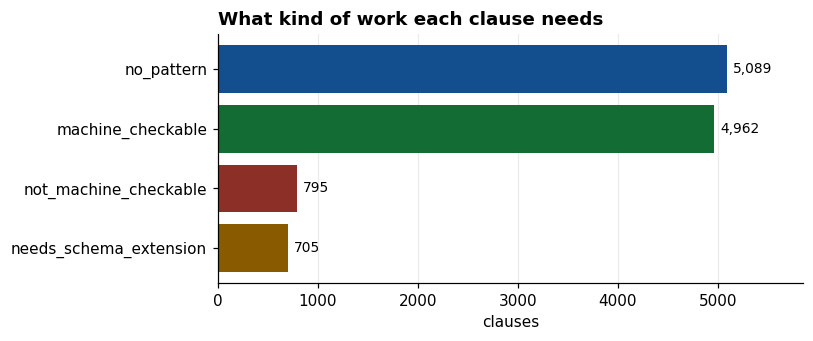

In [6]:
counts = df.label.value_counts()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
colors = {'machine_checkable': YES, 'no_pattern': BRAND,
          'needs_schema_extension': MAYBE, 'not_machine_checkable': NO}
bars = ax.barh(counts.index[::-1], counts.values[::-1],
               color=[colors[i] for i in counts.index[::-1]])
for b, v in zip(bars, counts.values[::-1]):
    ax.text(v + 60, b.get_y() + b.get_height()/2, f'{v:,}', va='center', fontsize=9)
ax.set_xlim(0, counts.max() * 1.15)
ax.set_xlabel('clauses')
ax.set_title('What kind of work each clause needs', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 4 · Evaluation protocol

`StratifiedGroupKFold`, 5 folds, grouped on the dedup group. Stratified because
the two small classes are 6% each; grouped because of the duplicate sentences.

**Macro-F1**, never accuracy — a model that predicted `no_pattern` for
everything would score 44% accuracy and be worthless.

In [7]:
def cv_macro_f1(X, y, groups, factory, n_splits=5):
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    scores, preds, truths = [], [], []
    for tr, te in cv.split(X, y, groups):
        m = factory(); m.fit(X[tr], y[tr])
        p = m.predict(X[te])
        scores.append(f1_score(y[te], p, average='macro'))
        preds.append(p); truths.append(y[te])
    return np.array(scores), np.concatenate(truths), np.concatenate(preds)

y = df.label.to_numpy()
groups = df.group.to_numpy()
Xs = df[structural_cols].to_numpy(dtype=float)
Xb = df[structural_cols + cue_cols].to_numpy(dtype=float)

results = {}
results['Baseline (majority)'], _, _ = cv_macro_f1(
    Xs, y, groups, lambda: DummyClassifier(strategy='most_frequent'))
results['A · structural only'], _, _ = cv_macro_f1(
    Xs, y, groups, lambda: DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=40, class_weight='balanced', random_state=SEED))
results['B · structural + cues'], b_true, b_pred = cv_macro_f1(
    Xb, y, groups, lambda: DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=25, class_weight='balanced', random_state=SEED))

tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
Xc = tfidf.fit_transform(df.text).toarray()
results['C · TF-IDF (reference)'], _, _ = cv_macro_f1(
    Xc, y, groups, lambda: DecisionTreeClassifier(
        max_depth=18, min_samples_leaf=5, class_weight='balanced', random_state=SEED))

for k, v in results.items():
    print(f'{k:<26} macro-F1 {v.mean():.3f} ± {v.std():.3f}')

Baseline (majority)        macro-F1 0.153 ± 0.000
A · structural only        macro-F1 0.332 ± 0.021
B · structural + cues      macro-F1 0.610 ± 0.010
C · TF-IDF (reference)     macro-F1 0.796 ± 0.011


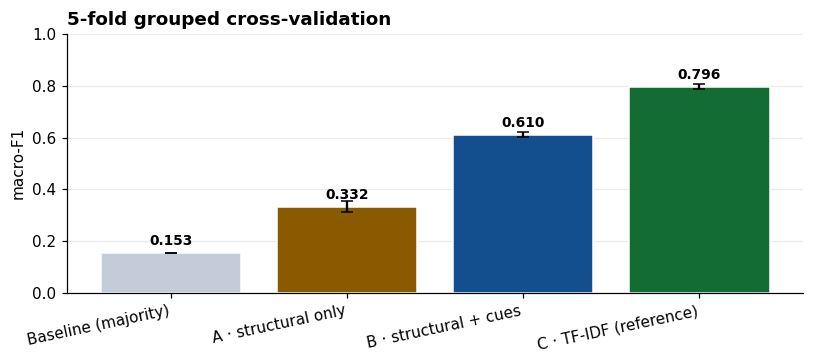

In [8]:
names = list(results); means = [results[n].mean() for n in names]; stds = [results[n].std() for n in names]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.bar(names, means, yerr=stds, capsize=4,
              color=['#c3ccd8', MAYBE, BRAND, YES], edgecolor='white')
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, m + 0.03, f'{m:.3f}', ha='center', fontweight='bold', fontsize=9)
ax.set_ylim(0, 1.0); ax.set_ylabel('macro-F1')
ax.set_title('5-fold grouped cross-validation', loc='left', fontweight='bold')
plt.xticks(rotation=12, ha='right'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

### Reading the numbers

**Model A matters most.** It uses only features the proposer never inspects, yet
it more than doubles the baseline. So the four classes are not purely regex
artefacts — clause *shape* genuinely differs between them. That is the result
that answers the circularity objection.

**Model C is the ceiling, and the trade.** TF-IDF wins by a wide margin, but a
3,000-feature tree cannot be read, checked, or defended by a reviewer. In a
system whose entire thesis is that every decision must be inspectable, an
uninterpretable triage model is the wrong tool even where it scores better.

## 5 · Where Model B is wrong

Per-class numbers, pooled over all five folds. The weak class is visible and is
reported rather than tuned away.

In [9]:
print(classification_report(b_true, b_pred, digits=3))

                        precision    recall  f1-score   support

     machine_checkable      0.815     0.594     0.687      4962
needs_schema_extension      0.210     0.633     0.315       705
            no_pattern      0.735     0.697     0.716      5089
 not_machine_checkable      0.656     0.810     0.725       795

              accuracy                          0.657     11551
             macro avg      0.604     0.683     0.611     11551
          weighted avg      0.732     0.657     0.679     11551



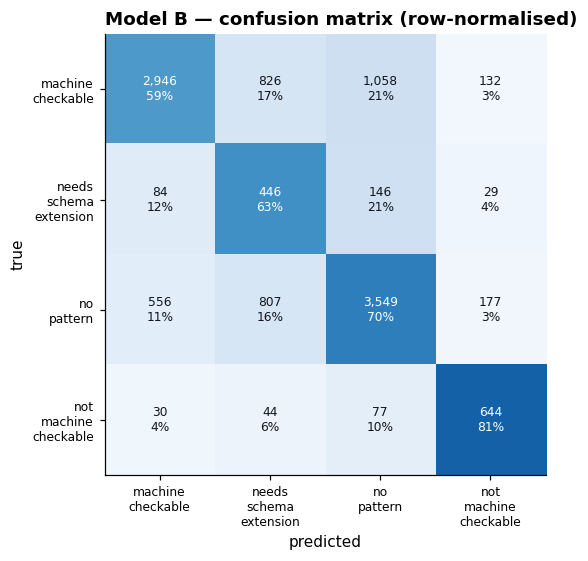

In [10]:
labels_sorted = sorted(df.label.unique())
cm = confusion_matrix(b_true, b_pred, labels=labels_sorted)
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
short = [l.replace('_', '\n') for l in labels_sorted]
ax.set_xticks(range(len(labels_sorted)), short, fontsize=8)
ax.set_yticks(range(len(labels_sorted)), short, fontsize=8)
for i in range(len(labels_sorted)):
    for j in range(len(labels_sorted)):
        ax.text(j, i, f'{cm[i,j]:,}\n{cmn[i,j]:.0%}', ha='center', va='center',
                fontsize=8, color='white' if cmn[i, j] > 0.5 else '#12151b')
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title('Model B — confusion matrix (row-normalised)', loc='left', fontweight='bold')
ax.grid(False)
plt.tight_layout(); plt.show()

`needs_schema_extension` is the weak class: recall is decent but precision is
poor, so the model over-predicts it. That is what `class_weight='balanced'` buys
— it lifts recall on a 705-example class by paying in false positives.

For this application that is the right side to err on: a clause wrongly flagged
as *needing a new profile field* costs a reviewer a few seconds to dismiss, while
a missed one is a field that never gets added and a whole family of schemes that
can never decide anything. The cost is asymmetric, so the errors should be too.

## 6 · What the tree actually splits on

The reason for choosing a single decision tree over a random forest: you can
read it. A forest would score better and explain nothing.

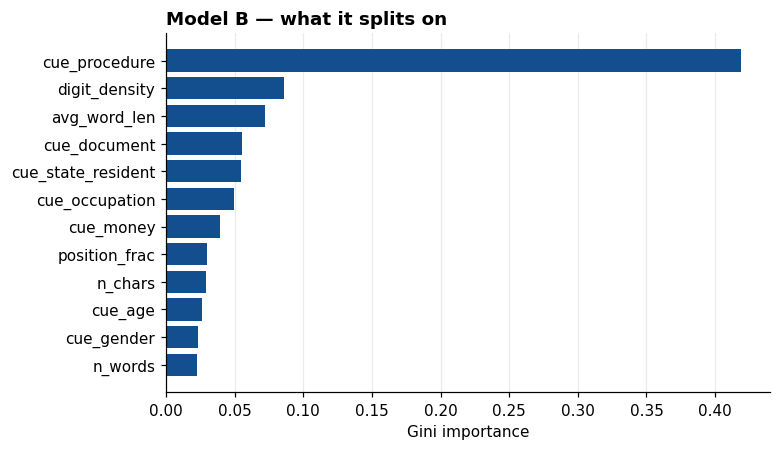

cue_procedure         0.419
digit_density         0.086
avg_word_len          0.072
cue_document          0.055
cue_state_resident    0.055
cue_occupation        0.050
cue_money             0.039
position_frac         0.030
n_chars               0.029
cue_age               0.026
cue_gender            0.023
n_words               0.022
dtype: float64

In [11]:
final = DecisionTreeClassifier(max_depth=10, min_samples_leaf=25,
                               class_weight='balanced', random_state=SEED).fit(Xb, y)
imp = (pd.Series(final.feature_importances_, index=structural_cols + cue_cols)
       .sort_values(ascending=False).head(12))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.barh(imp.index[::-1], imp.values[::-1], color=BRAND)
ax.set_xlabel('Gini importance')
ax.set_title('Model B — what it splits on', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
imp.round(3)

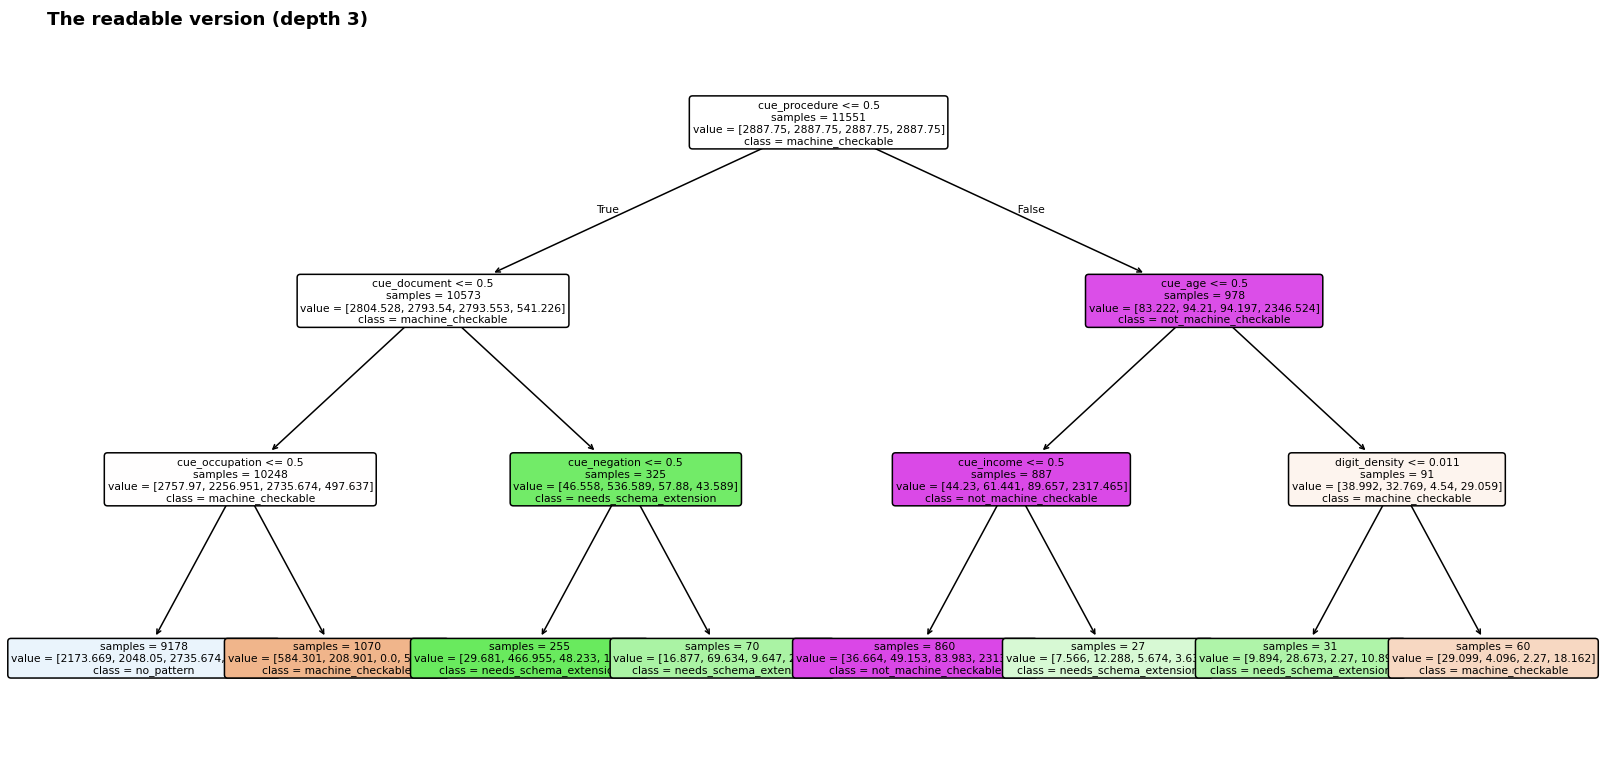

|--- cue_procedure <= 0.50
|   |--- cue_document <= 0.50
|   |   |--- cue_occupation <= 0.50
|   |   |   |--- class: no_pattern
|   |   |--- cue_occupation >  0.50
|   |   |   |--- class: machine_checkable
|   |--- cue_document >  0.50
|   |   |--- cue_negation <= 0.50
|   |   |   |--- class: needs_schema_extension
|   |   |--- cue_negation >  0.50
|   |   |   |--- class: needs_schema_extension
|--- cue_procedure >  0.50
|   |--- cue_age <= 0.50
|   |   |--- cue_income <= 0.50
|   |   |   |--- class: not_machine_checkable
|   |   |--- cue_income >  0.50
|   |   |   |--- class: needs_schema_extension
|   |--- cue_age >  0.50
|   |   |--- digit_density <= 0.01
|   |   |   |--- class: needs_schema_extension
|   |   |--- digit_density >  0.01
|   |   |   |--- class: machine_checkable



In [12]:
shallow = DecisionTreeClassifier(max_depth=3, min_samples_leaf=25,
                                 class_weight='balanced', random_state=SEED).fit(Xb, y)
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(shallow, feature_names=structural_cols + cue_cols,
          class_names=shallow.classes_, filled=True, rounded=True,
          impurity=False, fontsize=7, ax=ax)
ax.set_title('The readable version (depth 3)', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

print(export_text(shallow, feature_names=structural_cols + cue_cols, max_depth=3))

The root split is `cue_procedure` — whether the sentence mentions applying,
submitting, a portal or registration. That is exactly the right first question:
those clauses describe *how to apply*, not *who qualifies*, and they are the
largest source of un-checkable text in the corpus. The model rediscovering that
on its own is a small piece of evidence that the category is real.

---

# Part 2 · Model selection

Part 1 optimised for a tree a reviewer could read. That was the wrong objective,
and it is worth saying why rather than quietly swapping the model.

This model **orders a review queue**. It decides which clause a human looks at
third rather than ninth; the human then reads the clause; no citizen's
eligibility depends on any of it. The cost of a bad ordering is a few wasted
seconds. Interpretability is not what should be maximised here — accuracy is.

(Where auditability genuinely *is* the point — deciding whether a citizen
qualifies — there is no model at all, and that has not changed.)

So `ml/models.py` runs a proper comparison: the same grouped splits for every
candidate, a held-out 20% test set split on groups and touched exactly once, and
macro-F1 throughout. It takes about seven minutes, so this notebook reads the
recorded results rather than re-running them — the script is checked in beside
this file and is the source of truth.

In [13]:
selection = json.loads(Path('model_selection.json').read_text())
card = json.loads(Path('model_card.json').read_text())

rows = [(name, v['mean'], v['std'], v['seconds']) for name, v in selection['cv_macro_f1'].items()]
rows.sort(key=lambda r: r[1])
comparison = pd.DataFrame(rows, columns=['model', 'macro_f1', 'std', 'fit_seconds'])

print(f"dev {selection['dev_size']:,} · held-out test {selection['test_size']:,} "
      f"· {selection['n_features']:,} features")
comparison.set_index('model').round(3)

dev 9,236 · held-out test 2,315 · 50,601 features


,macro_f1,std,fit_seconds
model,,,
Baseline (majority),0.153,0.000,2.118
Decision tree,0.835,0.006,22.669
Random forest,0.883,0.008,80.210
Logistic regression,0.901,0.006,34.157
Linear SVM,0.908,0.005,9.214
Hist gradient boosting,0.933,0.005,294.793


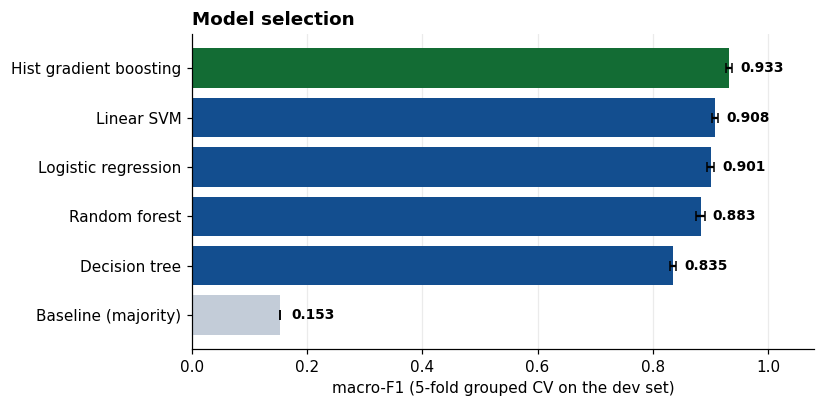

winner: Hist gradient boosting
held-out test macro-F1: 0.932  (dev CV 0.933 — close, so selection did not overfit the cross-validation)


In [14]:
fig, ax = plt.subplots(figsize=(7.6, 3.8))
colors = [YES if n == selection['winner'] else ('#c3ccd8' if 'Baseline' in n else BRAND)
          for n in comparison.model]
bars = ax.barh(comparison.model, comparison.macro_f1, xerr=comparison['std'], color=colors, capsize=3)
for b, v in zip(bars, comparison.macro_f1):
    ax.text(v + 0.02, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center',
            fontsize=9, fontweight='bold')
ax.set_xlim(0, 1.08)
ax.set_xlabel('macro-F1 (5-fold grouped CV on the dev set)')
ax.set_title('Model selection', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

print(f"winner: {selection['winner']}")
print(f"held-out test macro-F1: {selection['holdout_macro_f1']:.3f}  (dev CV "
      f"{selection['cv_macro_f1'][selection['winner']]['mean']:.3f} — close, so selection "
      "did not overfit the cross-validation)")

Gradient boosting wins, and the held-out score lands within a thousandth of the
dev estimate — the selection did not overfit the cross-validation.

The gap from the readable tree is the part worth noticing: **0.610 → 0.934**.
That is not a tuning difference. It is the difference between a model useful for
ordering a ten-thousand-item queue and one that is not.

## What actually ships

The app does not run this model. It reads a lookup table.

Porting an 800-tree ensemble over TF-IDF features to TypeScript would mean a
multi-megabyte model file, a hand-written vectoriser, and a standing risk that
the Python and TypeScript feature extraction drift apart — at which point every
prediction is quietly wrong and nothing raises an error. None of it is necessary,
because the corpus only changes when `npm run ingest` runs.

So `ml/predict_all.py` classifies every clause once and writes
`src/triage/predictions.json`. Crucially, **every prediction in that table is
out-of-fold**: five grouped folds, each clause classified by the fold that never
saw it, with the vectoriser refitted per fold so no test-fold vocabulary leaks
in. The number below describes exactly the predictions the running app serves.

In [15]:
per_class = pd.DataFrame(card['per_class']).T.loc[
    ['machine_checkable', 'no_pattern', 'not_machine_checkable', 'needs_schema_extension'],
    ['precision', 'recall', 'f1-score', 'support']
]
print(f"shipped table: {card['n_clauses']:,} clauses · "
      f"out-of-fold macro-F1 {card['macro_f1_out_of_fold']:.3f}\n")
per_class.round(3)

shipped table: 11,551 clauses · out-of-fold macro-F1 0.934



,precision,recall,f1-score,support
machine_checkable,0.965,0.933,0.949,4962.0
no_pattern,0.928,0.973,0.950,5089.0
not_machine_checkable,0.932,0.937,0.935,795.0
needs_schema_extension,0.968,0.848,0.904,705.0


---

# Part 3 · Constraint prediction — ML that writes the rules

Parts 1 and 2 built a model that sorts a queue. Useful, but peripheral: delete it
and every citizen-facing screen is byte-identical.

This part puts a model on the path that matters.

## The bottleneck

The rule proposer is a bank of regexes. When one matches a clause it drafts a
constraint; when none matches, the clause reaches a human with **nothing**, and
they must read the sentence and formalise it from scratch. That pile is why the
corpus has zero approved clauses and the engine can decide nothing for anyone.

A regex fails because it does not recognise the *phrasing* — which says nothing
about whether the clause is formalisable. *"Applicant must be a woman farmer
owning not more than 2 hectares"* is perfectly checkable; no pattern happened to
match it.

So: learn the structure from the 4,962 clauses a pattern did match, and predict
it for the ones where none did.

## Three heads

| Head | Predicts | Type |
|---|---|---|
| `fields` | which profile fields the clause tests | multi-label, 8 active |
| `operators` | which comparisons it uses | multi-label, 7 active |
| `exclusion` | whether it **disqualifies** rather than qualifies | binary |

Structure only. The values — 18, 2 hectares, "telangana" — come from the existing
numeric and lexicon parsers, which are good at values and bad at recognising
phrasing. The split runs along the line where each side is strong.

Getting `exclusion` backwards inverts the meaning of a rule, which is why it is
predicted rather than inferred.

In [16]:
cres = json.loads(Path('constraint_results.json').read_text())
ccard = json.loads(Path('constraint_card.json').read_text())

print(f"trained on {cres['n_labelled']:,} clauses with a proposer-drafted constraint")
print(f"predicting for {cres['n_unlabelled']:,} that had none\n")

pd.DataFrame(cres['results']).T[['micro_f1', 'macro_f1', 'exact_match']].round(3)

trained on 4,962 clauses with a proposer-drafted constraint
predicting for 6,589 that had none



,micro_f1,macro_f1,exact_match
fields,0.953,0.944,0.899
operators,0.923,0.844,0.843
exclusion,0.971,0.868,0.971


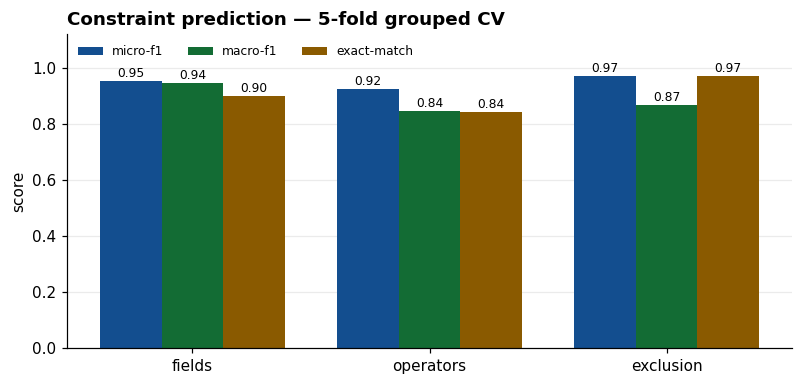

In [17]:
heads = list(cres['results'])
metrics = ['micro_f1', 'macro_f1', 'exact_match']
x = np.arange(len(heads)); w = 0.26

fig, ax = plt.subplots(figsize=(7.4, 3.6))
for i, m in enumerate(metrics):
    vals = [cres['results'][h][m] for h in heads]
    bars = ax.bar(x + (i - 1) * w, vals, w, label=m.replace('_', '-'),
                  color=[BRAND, YES, MAYBE][i])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.015, f'{v:.2f}', ha='center', fontsize=8)
ax.set_xticks(x, heads); ax.set_ylim(0, 1.12); ax.set_ylabel('score')
ax.set_title('Constraint prediction — 5-fold grouped CV', loc='left', fontweight='bold')
ax.legend(frameon=False, fontsize=8, ncols=3)
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Exact-set match on fields is 0.899** — for nine clauses in ten the model names
the complete set of profile fields correctly, not just some of them. That is the
number that matters, because a reviewer accepting a draft accepts the whole
thing.

Operators are harder (0.843 exact) and the rare ones — `lt`, `gt`, `in` — carry
precision around 0.65. They are also the ones where a mistake is cheap to spot:
a reviewer reading "not more than 2 hectares" sees immediately whether `lte` is
right.

`exclusion` is 97.1% accurate overall but only 0.75 F1 on the positive class —
250 examples is thin, and the model over-flags. Given that a missed disqualifier
silently inverts a rule while a false one is visible on inspection, erring toward
over-flagging is the right direction.

## What it recovers

blank clauses handed to a reviewer : 6,589
model drafted structure for        : 1,926  (29.2%)
threshold                          : p >= 0.6



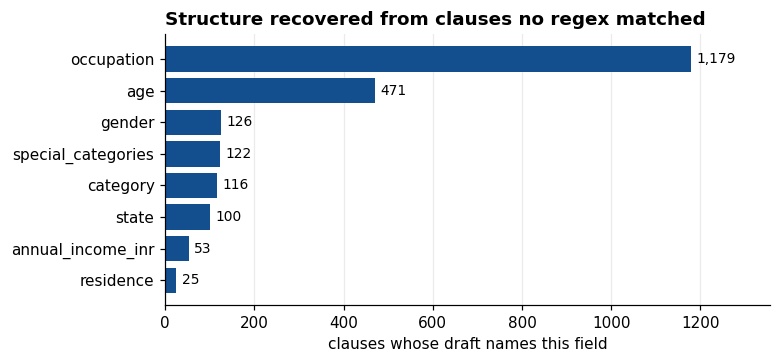

In [18]:
print(f"blank clauses handed to a reviewer : {ccard['predicted_for']:,}")
print(f"model drafted structure for        : {ccard['drafted']:,}  ({ccard['coverage']:.1%})")
print(f"threshold                          : p >= {ccard['thresholds']['field']}\n")

tally = pd.Series(ccard['field_tally']).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.barh(tally.index[::-1], tally.values[::-1], color=BRAND)
for i, v in enumerate(tally.values[::-1]):
    ax.text(v + 12, i, f'{v:,}', va='center', fontsize=9)
ax.set_xlim(0, tally.max() * 1.15)
ax.set_xlabel('clauses whose draft names this field')
ax.set_title('Structure recovered from clauses no regex matched', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Coverage is **29%**, not 90%, and the gap is the honest part of this result.

The threshold is set at p ≥ 0.60 deliberately: below it the model is guessing,
and a wrong field sends a reviewer down the wrong path — worse than the blank
form they already had. The 71% left untouched are exactly where they were.

There is also a **distribution shift** that the cross-validation cannot measure.
Those scores came from clauses the regexes matched; these are the clauses they
missed, which are systematically the awkward ones. The CV numbers are an upper
bound on performance here, not an estimate of it. The model also leans on
`occupation`, its majority field, and some drafts will be wrong for that reason.

Which is the whole argument for why this is a **draft**. Every prediction lands
in front of a named reviewer who approves, corrects or rejects it — the same gate
every regex-proposed constraint already passes through. `isDecisive()` still
requires `annotation_state === 'approved'`, and `tests/proposals.test.ts` asserts
that a model-drafted constraint does not make a clause decisive.

The model turns *"read this clause and start from nothing"* into *"check whether
these three fields are right"*. It shortens the queue. It does not shorten the
review.

## Conclusions

1. **The categories are real.** Model A, built only from features the rule
   proposer never inspects, more than doubles the baseline. The four triage
   classes reflect genuine differences in how clauses are written.
2. **Optimise for the job the model actually does.** The readable tree scored
   0.610; gradient boosting scores **0.934** out-of-fold. Interpretability was
   the wrong objective for a component that orders a worklist and decides
   nothing — the reviewer reads the clause either way.
3. **This model triages; it never decides.** Eligibility stays with the rule
   engine and its human approvals. The contribution is throughput on a
   10,051-clause backlog, not a verdict. That boundary is precisely why trading
   away interpretability was acceptable here and nowhere else.
4. **The honest caveat.** Labels come from the rule proposer, so every number
   above measures agreement with a rule system, not correctness. The real
   evaluation becomes possible once reviewers have approved a few hundred
   clauses by hand — at which point the same pipeline can be retrained on human
   labels, and *that* model would be measuring something else entirely.